# 크립에서 평문까지 — 봄베 조작 따라 하기

이 노트북은 블레츨리 파크의 봄베 조작자가 하던 일을 순서대로 따라 한다.

| 단계 | 실제 작업 | 이 노트북 |
|---|---|---|
| 1 | 독일군이 에니그마로 전문을 암호화한다 | `Enigma` |
| 2 | 해독자가 평문 일부를 추측하고(크립) 암호문 아래에 맞춰 본다 | `possible_offsets` |
| 3 | 크립과 암호문의 글자 관계를 그래프로 그린다(메뉴) | `Menu` |
| 4 | 메뉴대로 봄베를 배선하고 드럼을 돌려 정지 위치를 적는다 | `Bombe.plug_up`, `Bombe.run` |
| 5 | 체킹 머신으로 정지를 검증하고 키 전체를 복원해 해독한다 | `Stop.check` |

암호 해독에 대한 사전 지식은 필요 없다. 필요한 용어는 처음 나올 때 설명한다.

**표기.** 역사적 사실 뒤의 `[@키]`는 `report/references.bib`의 인용 키다. 근거의 자세한 내용과 출처 등급은 `docs/reference/bombe-mechanics.md`에 정리되어 있다.

**실행 환경.** `christopher` 패키지가 설치된 가상환경의 커널로 실행한다(빌드 방법은 저장소의 `README.md`). 전체 실행은 몇 초면 끝난다.

In [1]:
import json
import time
from collections import Counter
from pathlib import Path

from christopher import Bombe, Enigma, Menu, possible_offsets, search

# 저장소 루트 (노트북을 어느 폴더에서 실행하든 data/를 찾는다)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "vectors").exists())

## 1. 에니그마: 공격 대상

에니그마는 글자 하나를 누를 때마다 다른 치환표로 바꿔 주는 기계다. 하루의 키는 네 가지로 이루어진다.

| 설정 | 뜻 | 경우의 수 (Enigma I) |
|---|---|---|
| 로터 순서 | 로터 I–V 중 3개를 왼쪽·가운데·오른쪽에 끼우는 순서 | 60 |
| 링 설정 | 로터 겉의 글자 링을 내부 배선에 대해 돌려 둔 정도 | 26³ |
| 시작 위치 | 전문을 치기 시작할 때 창에 보이는 세 글자 | 26³ |
| 플러그보드(스테커) | 글자 쌍을 맞바꾸는 케이블 10개 | 약 1.5 × 10¹⁴ |

전류는 `플러그보드 → 로터 3개 → 반사판 → 로터 3개(역방향) → 플러그보드` 순으로 흐른다.
플러그보드의 경우의 수가 압도적으로 커서 무차별 대입은 불가능하다. 봄베는 플러그보드를 **대입하지 않고 논리적으로 추론**해서 이 문제를 피한다.

먼저 "독일군 통신병" 역할로 전문 하나를 암호화한다. 이 키는 뒤에서 모르는 것으로 치고 찾아낼 것이다.

In [2]:
# 그날의 키 (해독자는 모른다)
SECRET = dict(
    rotors=("III", "V", "II"),          # 왼쪽, 가운데, 오른쪽
    reflector="B",
    rings="GMC",
    positions="KDC",
    plugboard="AQ BZ CR DM EV FW GK HN IU JP",
)

# 평문. 독일군은 띄어쓰기 대신 X를 쓰고 움라우트는 AE/OE/UE로 풀어 썼다.
PLAIN = (
    "ANXOBERKOMMANDODERWEHRMACHTXWETTERVORHERSAGEFUERDIENORDSEEXHEUTEKLAR"
    "XWINDAUSWESTXSTAERKEDREIXSICHTWEITEZEHNSEEMEILENXENDE"
)

enigma = Enigma("enigma-i", **SECRET)
CIPHER = enigma.encrypt(PLAIN)

print("평문  :", PLAIN)
print("암호문:", CIPHER)
print(f"글자 수 {len(CIPHER)}, 창 글자 {enigma.start} -> {enigma.positions}")

평문  : ANXOBERKOMMANDODERWEHRMACHTXWETTERVORHERSAGEFUERDIENORDSEEXHEUTEKLARXWINDAUSWESTXSTAERKEDREIXSICHTWEITEZEHNSEEMEILENXENDE
암호문: HKFLOGGSLVIXBTVWVEHCVVOMBAHUILZLIIUFMWAJNWTUMXQIRTQVQPUUYQFUHYLMDYHYEGGCXXMIIMGUSLHUQWOQWOCCGKKFOKZHPRMNWOOUGSTFQTYHHQUUR
글자 수 121, 창 글자 KDC -> KIT


### 에니그마의 두 가지 성질

봄베가 이용하는 약점은 둘이다.

1. **상호성.** 같은 설정에서 A가 Q로 바뀌면 Q는 A로 바뀐다. 그래서 암호화와 복호화가 같은 조작이다.
2. **어떤 글자도 자기 자신으로 암호화되지 않는다.** 반사판이 전류를 반드시 다른 선으로 되돌려 보내기 때문이다.

In [3]:
# 1. 상호성: 같은 키로 암호문을 치면 평문이 나온다
assert enigma.reset().decrypt(CIPHER) == PLAIN

# 2. 평문과 암호문의 같은 자리에 같은 글자가 오는 일은 없다
same = sum(p == c for p, c in zip(PLAIN, CIPHER))
print(f"{len(PLAIN)}글자 중 평문 글자 = 암호문 글자인 자리: {same}개")

# 무작위 치환이라면 121글자 중 평균 121/26 = 약 4.7개가 일치해야 한다
print(f"(무작위 치환일 때의 기댓값: {len(PLAIN) / 26:.1f}개)")

121글자 중 평문 글자 = 암호문 글자인 자리: 0개
(무작위 치환일 때의 기댓값: 4.7개)


### 로터의 전진과 이중 스테핑

키를 누르면 **암호화 전에** 로터가 먼저 움직인다. 오른쪽 로터는 매번 한 칸 가고, 노치 위치를 지날 때 가운데 로터를 한 칸 민다. 가운데 로터가 자기 노치 위치에 오면 다음 키에서 왼쪽 로터를 밀면서 **자신도 한 칸 더** 간다. 이것이 이중 스테핑이다.

로터 III의 노치는 V, 로터 II의 노치는 E에 있다. 창 글자 `ADU`에서 키를 네 번 누르면:

In [4]:
e = Enigma("enigma-i", rotors=("I", "II", "III"), positions="ADU")
windows = [e.positions]
for _ in range(4):
    e.encrypt("A")
    windows.append(e.positions)
print(" -> ".join(windows))
# ADV -> AEW: 오른쪽 로터가 V를 지나며 가운데를 민다
# AEW -> BFX: 가운데 로터가 E에서 왼쪽을 밀고 자신도 한 칸 더 간다 (이중 스테핑)

ADU -> ADV -> AEW -> BFX -> BFY


가운데 로터는 오른쪽 로터가 26칸 갈 때 한 번만 움직인다. 이 사실은 6절에서 중요해진다. 봄베는 "크립 구간 안에서는 가운데 로터가 움직이지 않는다"고 가정하기 때문이다 [@us6812report1944].

## 2. 크립 정렬

여기서부터는 해독자의 입장이다. 가진 것은 암호문 `CIPHER`뿐이다.

**크립(crib)** 은 평문에 들어 있을 것으로 추측하는 문구다. 독일군 전문은 형식이 정해져 있어 추측이 가능했다. 기상 통보에는 `WETTERVORHERSAGE`(일기예보)가 거의 반드시 들어갔다.

문제는 이 문구가 암호문의 **어디에** 놓이는가다. 여기서 1절의 둘째 성질을 쓴다. 크립을 암호문 아래에 놓았을 때 위아래 글자가 같은 자리가 하나라도 있으면 그 위치는 불가능하다.

In [5]:
CRIB = "WETTERVORHERSAGE"

offsets = possible_offsets(CIPHER, CRIB)
total = len(CIPHER) - len(CRIB) + 1
print(f"크립을 놓을 수 있는 위치 {total}곳 중 {len(offsets)}곳이 가능, {total - len(offsets)}곳은 배제")
print("가능한 위치:", offsets)


def show_alignment(offset):
    "암호문 일부와 그 아래 놓은 크립. 같은 글자가 겹치는 자리에 ^ 표시."
    segment = CIPHER[offset:offset + len(CRIB)]
    marks = "".join("^" if a == b else " " for a, b in zip(segment, CRIB))
    verdict = "불가능" if "^" in marks else "가능"
    print(f"\n위치 {offset}: {verdict}\n  암호문 {segment}\n  크립   {CRIB}\n         {marks}")


show_alignment(2)    # 배제되는 예
show_alignment(28)   # 실제 위치

크립을 놓을 수 있는 위치 106곳 중 60곳이 가능, 46곳은 배제
가능한 위치: [0, 1, 4, 5, 6, 18, 19, 20, 21, 22, 23, 24, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 38, 42, 44, 48, 49, 50, 52, 54, 59, 60, 61, 62, 63, 65, 66, 69, 70, 71, 72, 74, 75, 76, 77, 80, 81, 83, 84, 86, 87, 91, 92, 95, 100, 101, 102, 103, 105]

위치 2: 불가능
  암호문 FLOGGSLVIXBTVWVE
  크립   WETTERVORHERSAGE
                        ^

위치 28: 가능
  암호문 ILZLIIUFMWAJNWTU
  크립   WETTERVORHERSAGE
                         


글자 하나가 겹칠 확률은 1/26이므로, 16글자 크립이 우연히 살아남을 확률은 (25/26)¹⁶ ≈ 53%다. 크립이 길수록 더 많은 위치가 배제된다.

남은 위치 중 어느 것이 맞는지는 이 방법만으로는 알 수 없다. 실제로는 전문 형식에 대한 지식(예: 일기예보는 수신자 표기 바로 뒤에 온다)으로 위치를 좁혔고, 그래도 남으면 후보마다 메뉴를 만들어 봄베를 돌렸다. 여기서는 위치 28을 택했다고 하고 진행한다.

## 3. 메뉴 작성

크립을 정렬하면 글자 쌍의 목록이 생긴다. 크립의 k번째 글자가 평문 `P`, 암호문 `C`이면 "k번째 위치의 에니그마가 P를 C로 바꾼다"는 뜻이다. 글자를 점, 이 관계를 선으로 그린 그래프가 **메뉴(menu)** 다. 선에는 크립 안에서의 위치 번호를 적는다.

In [6]:
OFFSET = 28
full_menu = Menu.from_crib(CIPHER, CRIB, OFFSET)
print(full_menu)
print("\n서로 연결된 글자 묶음:", full_menu.components)

menu at offset 28: 16 edges, 18 letters, 1 loops, span 16, test letter E (input wire A)
    1: W - I
    2: E - L
    3: T - Z
    4: T - L
    5: E - I
    6: R - I
    7: V - U
    8: O - F
    9: R - M
   10: H - W
   11: E - A
   12: R - J
   13: S - N
   14: A - W
   15: G - T
   16: E - U

서로 연결된 글자 묶음: ['AEGHIJLMRTUVWZ', 'FO', 'NS']


봄베에서는 선 하나에 **스크램블러(드럼 3개 한 벌, 플러그보드 없는 에니그마 한 대)** 하나가 필요하다. 영국 봄베는 스크램블러가 36개(12개 × 3뱅크)였고, 12개 이하 메뉴는 로터 순서 3개를 한 번에 돌릴 수 있었다 [@us6812report1944]. 또 전류가 흘러야 하므로 서로 떨어진 묶음(`FO`, `NS`)은 쓸 수 없다.

`select`는 한 덩어리로 연결되고 루프가 많은 부분 메뉴를 골라 준다.

In [7]:
menu = full_menu.select(14)
print(menu)

# 글자별 연결 (메뉴 그림을 글로 옮긴 것). 괄호 안은 크립 내 위치.
print("\n글자별 연결:")
neighbours = {}
for edge in menu.edges:
    neighbours.setdefault(edge.plain, []).append(f"{edge.cipher}({edge.pos + 1})")
    neighbours.setdefault(edge.cipher, []).append(f"{edge.plain}({edge.pos + 1})")
for letter in sorted(neighbours, key=lambda x: -len(neighbours[x])):
    print(f"  {letter}: {'  '.join(neighbours[letter])}")

menu at offset 28: 14 edges, 14 letters, 1 loops, span 16, test letter E (input wire A)
    1: W - I
    2: E - L
    3: T - Z
    4: T - L
    5: E - I
    6: R - I
    7: V - U
    9: R - M
   10: H - W
   11: E - A
   12: R - J
   14: A - W
   15: G - T
   16: E - U

글자별 연결:
  E: L(2)  I(5)  A(11)  U(16)
  W: I(1)  H(10)  A(14)
  I: W(1)  E(5)  R(6)
  T: Z(3)  L(4)  G(15)
  R: I(6)  M(9)  J(12)
  L: E(2)  T(4)
  U: V(7)  E(16)
  A: E(11)  W(14)
  Z: T(3)
  V: U(7)
  M: R(9)
  H: W(10)
  J: R(12)
  G: T(15)


### 메뉴를 읽는 법

- **루프(closure).** `E –(5)– I –(1)– W –(14)– A –(11)– E`처럼 출발한 글자로 돌아오는 경로다. 루프는 강한 제약이다. E의 스테커 짝을 하나 가정하고 루프를 한 바퀴 돌면 다시 E의 스테커 짝이 나와야 하는데, 틀린 드럼 위치에서는 대부분 다른 글자가 나와 모순이 된다. 루프가 하나 늘 때마다 거짓 정지가 약 1/26로 줄어든다.
- **테스트 글자(input).** 전류를 넣고 결과를 관찰하는 글자다. 연결이 가장 많은 글자를 고른다 [@us6812report1944]. 여기서는 `E`다.
- **입력 선(input wire).** 테스트 글자의 케이블 26선 중 전압을 거는 선. "E의 스테커 짝은 A다"라는 가설에 해당한다. 어느 선을 골라도 결과는 같다(4절).

이 메뉴는 글자 14개, 루프 1개다. 튜링의 추정표로는 이런 메뉴에서 로터 순서 하나당 거짓 정지가 약 1.6개 나온다(간접 인용) [@carter-stops; @wikipedia-bombe]. 4절에서 직접 세어 비교한다.

## 4. 봄베 배선과 구동

### 봄베가 하는 일

봄베는 로터 순서 하나에 대해 드럼 위치 26³ = 17,576가지를 차례로 지나가며, 위치마다 한 가지 질문에 답한다.

> 이 드럼 위치에서, 메뉴의 모든 관계를 동시에 만족하는 플러그보드가 존재할 수 있는가?

구조는 다음과 같다.

- 글자마다 **26선 케이블**이 하나씩 있다. 케이블 `E`의 `V`번 선에 전류가 흐른다는 것은 "E의 스테커 짝이 V라는 가설이 살아 있다(또는 그 가설에서 유도된다)"는 뜻이다. 26 × 26 = 676개 선의 통전 여부가 기계의 상태 전부다.
- 메뉴의 선마다 **스크램블러**가 두 글자의 케이블을 잇는다. 크립 위치 k의 스크램블러는 드럼을 기준 위치보다 k칸 앞서게 맞춘다.
- 테스트 글자 케이블의 한 선에 전압을 건다. 전류는 스크램블러를 거쳐 퍼지면서 그 가설의 **논리적 귀결 전부**를 통전시킨다.

### 정지 조건

테스트 글자 케이블(테스트 레지스터)의 26선을 본다 [@us6812report1944; @jackson-bh10].

| 테스트 레지스터 | 뜻 | 기계 |
|---|---|---|
| 26선 모두 통전 | 처음 가설에서 나머지 25가지 가설이 모두 유도됨. E의 짝은 하나뿐이어야 하므로 전부 모순 | 통과(계속 회전) |
| 25선 통전, 1선만 죽음 | 처음 가설은 틀렸지만, 죽은 선의 가설 하나는 모순에 휘말리지 않음 | **정지.** 죽은 선이 스테커 후보 |
| 1선만 통전 | 처음 가설이 우연히 맞아 모순이 퍼지지 않음 | **정지.** 그 선이 스테커 후보 |

정리하면 정지 조건은 "테스트 레지스터 26선이 전부 통전되지는 않음"이다. 틀린 가설 하나를 넣어 25가지를 한꺼번에 기각하는 것이 튜링의 착상이다. 전류가 순식간에 퍼지므로 가설을 하나씩 시험할 필요가 없다.

### 구동

메뉴를 배선하고(`plug_up`) Enigma I의 모든 로터 순서를 돌린다. 로터 순서 60가지에 반사판 B·C를 곱해 120가지다. 실제 봄베는 로터 순서 하나에 약 10분이 걸렸고 [@jackson-bh09], 봄베 여러 대가 서로 다른 로터 순서를 나눠 맡았다.

In [8]:
bombe = Bombe(model="enigma-i", diagonal_board=True).plug_up(menu)

t0 = time.perf_counter()
stops = bombe.run(wheel_orders="all")
elapsed = time.perf_counter() - t0

orders_run = bombe.positions_tested // 26**3
print(f"로터 순서 {orders_run}개, 드럼 위치 {bombe.positions_tested:,}곳을 {elapsed:.2f}초에 탐색")
print(f"정지 {len(stops)}회 (로터 순서당 평균 {len(stops) / orders_run:.2f}회, 튜링 추정표의 예상은 약 1.6회)")

per_order = Counter(str(s.wheel_order) for s in stops)
histogram = Counter(per_order.get(o, 0) for o in {str(s.wheel_order) for s in stops})
histogram[0] = orders_run - len(per_order)
print("로터 순서별 정지 횟수 분포:", dict(sorted(histogram.items())))

로터 순서 120개, 드럼 위치 2,109,120곳을 0.32초에 탐색
정지 157회 (로터 순서당 평균 1.31회, 튜링 추정표의 예상은 약 1.6회)
로터 순서별 정지 횟수 분포: {0: 35, 1: 37, 2: 28, 3: 16, 4: 4}


조작자는 정지할 때마다 **로터 순서, 드럼 글자 세 개, 테스트 글자의 스테커 후보**를 정지 전표에 적었다 [@us6812report1944]. 정지 목록의 앞부분은 다음과 같다.

In [9]:
print(f"{'번호':>4}  {'로터 순서':<12} {'드럼':<5} {'통전 선 수':>8}  스테커 후보")
for number, stop in enumerate(stops[:12], start=1):
    live = stop.test_register.bit_count()
    candidates = ",".join(stop.stecker_candidates)
    print(f"{number:>4}  {str(stop.wheel_order):<14} {stop.position:<6} {live:>6}/26     "
          f"{stop.test_letter}/{candidates}")
print(f"  ... (전체 {len(stops)}개)")

print("\n통전 선 수별 정지 횟수:", dict(Counter(s.test_register.bit_count() for s in stops)))

  번호  로터 순서        드럼      통전 선 수  스테커 후보
   1  B I-II-IV      BGQ        25/26     E/E
   2  B I-II-IV      OCL        25/26     E/F
   3  B I-II-V       QPG        25/26     E/N
   4  B I-II-V       WUN        25/26     E/K
   5  B I-III-II     EKM        25/26     E/C
   6  B I-IV-III     UIH        25/26     E/K
   7  B I-IV-III     VQH        25/26     E/N
   8  B I-IV-V       ISZ        25/26     E/D
   9  B I-V-II       DOC        25/26     E/L
  10  B I-V-III      INO        25/26     E/E
  11  B II-I-III     LSQ        25/26     E/E
  12  B II-I-IV      FCD        25/26     E/Z
  ... (전체 157개)

통전 선 수별 정지 횟수: {25: 155, 1: 2}


대부분 25선 통전(가설 `E/A`가 틀림)이고, 드물게 1선 통전(가설이 우연히 맞음)이 섞여 있다. 후보 `E/E`는 E에 플러그가 꽂혀 있지 않다(자기 자신과 짝)는 뜻이다.

**드럼 글자에 대한 주의.** 여기 표시되는 드럼 글자는 "크립 첫 글자를 암호화하는 순간의 로터 내부 배선 회전량(창 글자 − 링 설정)"을 A=0으로 적은 것이다. 실제 봄베의 지시 드럼은 눈금이 역순이고 드럼 종류별로 글자가 1–3칸 어긋나 있어 다른 글자가 표시된다 [@sale-ringstellung; @ekhall-hallenberg-tutorial]. 역사적 표기로의 변환은 아직 구현하지 않았다.

이 157개 중 진짜는 하나뿐이다. 나머지는 메뉴의 제약만으로는 걸러지지 않은 **거짓 정지**다. 5절의 체킹이 이를 걸러 낸다.

### 대각선 보드

지금까지 쓴 봄베에는 웰치먼의 **대각선 보드**가 켜져 있었다. 원리는 플러그보드의 대칭성이다. E의 짝이 V이면 V의 짝은 E다. 그래서 케이블 `E`의 `V`번 선과 케이블 `V`의 `E`번 선을 영구 배선으로 이어 둔다(모든 글자 쌍에 대해 325개) [@us6812report1944; @ellsbury1998bombe]. 이 배선은 메뉴에 없던 연결을 대량으로 만들어 주므로 모순이 훨씬 잘 퍼진다.

같은 메뉴, 같은 로터 순서에서 대각선 보드를 끄면 어떻게 되는지 본다.

In [10]:
ORDER = "B III-V-II"   # 비교용 로터 순서 하나

with_board = Bombe(diagonal_board=True).plug_up(menu).run(ORDER)
without_board = Bombe(diagonal_board=False).plug_up(menu).run(ORDER)

print(f"로터 순서 {ORDER}, 드럼 위치 {26**3:,}곳")
print(f"  대각선 보드 있음: 정지 {len(with_board):>6,}회")
print(f"  대각선 보드 없음: 정지 {len(without_board):>6,}회")

로터 순서 B III-V-II, 드럼 위치 17,576곳
  대각선 보드 있음: 정지      2회
  대각선 보드 없음: 정지 17,576회


대각선 보드가 없으면 **17,576곳 전부에서 정지한다.** 기계가 아무것도 걸러 내지 못한다는 뜻이다. 루프가 하나뿐인 메뉴에서는 전류가 루프를 따라 도는 것 말고는 퍼질 길이 없어 26선을 다 채우지 못하기 때문이다. 대각선 보드를 켜면 같은 메뉴로 2곳만 남는다.

튜링의 원래 설계는 루프가 3개 이상인 메뉴가 필요했고 그런 크립은 드물었다. 대각선 보드 덕분에 루프가 하나거나 없는 메뉴로도 봄베를 돌릴 수 있게 되었다 [@carter2010bombe].

### 통전 상태 들여다보기

`trace`는 한 드럼 위치에서 676개 선의 통전 상태를 돌려준다. 세 경우를 그려 본다. 가로줄이 케이블(글자), 세로줄이 그 케이블의 선이다.

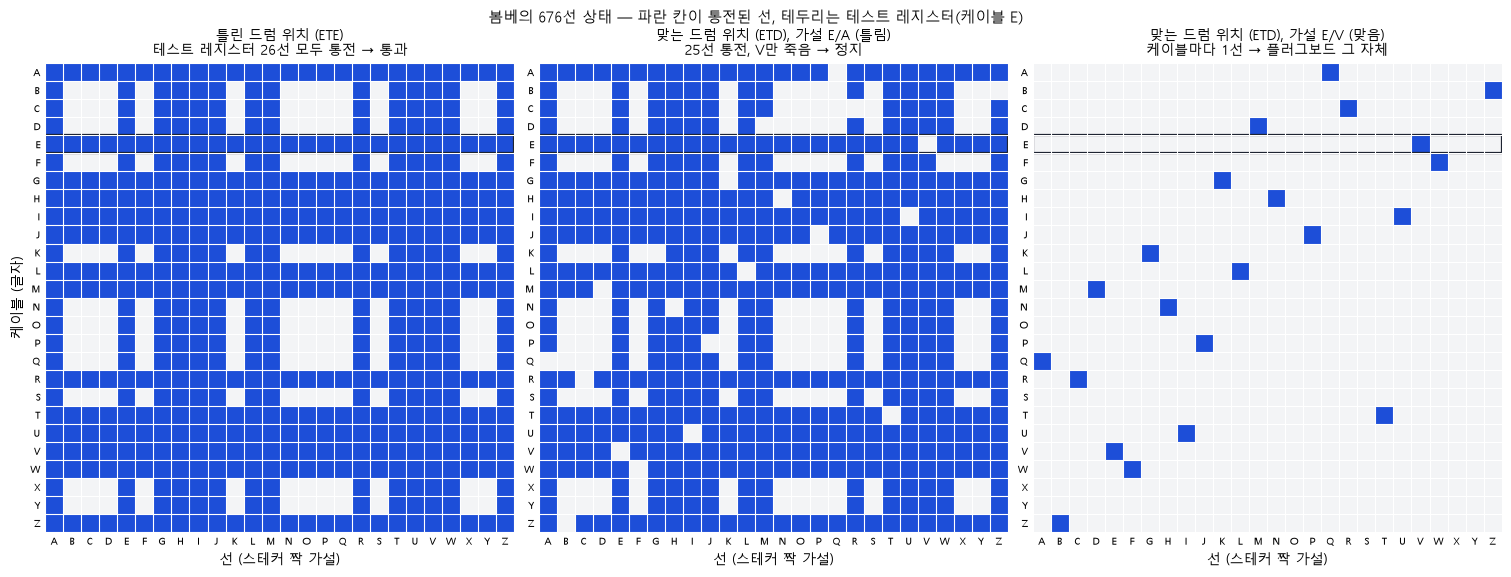

케이블 E: ABCDEFGHIJKLMNOPQRSTUVWXYZ   <- 틀린 드럼 위치 (ETE)
케이블 E: ABCDEFGHIJKLMNOPQRSTU.WXYZ   <- 맞는 드럼 위치 (ETD), 가설 E/A (틀림)
케이블 E: .....................V....   <- 맞는 드럼 위치 (ETD), 가설 E/V (맞음)


In [11]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

plt.rcParams["font.family"] = ["Malgun Gothic", "DejaVu Sans"]   # 한글 글꼴 (Windows)
plt.rcParams["axes.unicode_minus"] = False

LETTERS = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
true_stop = next(s for s in with_board if s.position == "ETD")
test_row = LETTERS.index(menu.test_letter)

panels = [
    ("틀린 드럼 위치 (ETE)\n테스트 레지스터 26선 모두 통전 → 통과",
     bombe.trace(ORDER, "ETE", matrix=True)),
    ("맞는 드럼 위치 (ETD), 가설 E/A (틀림)\n25선 통전, V만 죽음 → 정지",
     true_stop.trace(matrix=True)),
    ("맞는 드럼 위치 (ETD), 가설 E/V (맞음)\n케이블마다 1선 → 플러그보드 그 자체",
     true_stop.trace(input_wire="V", matrix=True)),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5.6), constrained_layout=True)
cmap = ListedColormap(["#f3f4f6", "#1d4ed8"])     # 죽은 선 / 통전된 선
for ax, (title, grid) in zip(axes, panels):
    ax.imshow(np.array(grid, dtype=int), cmap=cmap, vmin=0, vmax=1)
    ax.set_xticks(range(26), LETTERS, fontsize=7)
    ax.set_yticks(range(26), LETTERS, fontsize=7)
    ax.set_xticks(np.arange(-0.5, 26), minor=True)
    ax.set_yticks(np.arange(-0.5, 26), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="both", length=0)
    ax.set_xlabel("선 (스테커 짝 가설)")
    ax.set_title(title, fontsize=10)
    # 테스트 레지스터 = 테스트 글자의 케이블
    ax.add_patch(Rectangle((-0.5, test_row - 0.5), 26, 1, fill=False, edgecolor="#111827", linewidth=1.6))
    for spine in ax.spines.values():
        spine.set_visible(False)
axes[0].set_ylabel("케이블 (글자)")
fig.suptitle("봄베의 676선 상태 — 파란 칸이 통전된 선, 테두리는 테스트 레지스터(케이블 E)", fontsize=11)
plt.show()

for title, grid in panels:
    live = "".join(l if on else "." for l, on in zip(LETTERS, grid[test_row]))
    print(f"케이블 {menu.test_letter}: {live}   <- {title.splitlines()[0]}")

- **왼쪽.** 틀린 위치에서는 가설 하나가 메뉴 글자의 케이블을 전부 채운다. 메뉴에 없는 글자의 케이블에도 대각선 보드를 거쳐 전류가 들어간다.
- **가운데.** 맞는 위치에서는 틀린 가설 25개가 서로를 통전시키지만, 참인 가설(케이블 E의 V선)에는 닿지 못한다. 참인 명제는 거짓 명제들의 귀결로 끌려 들어가지 않는 셈이다. 메뉴 글자의 케이블마다 죽은 선이 하나씩 있고, 그것이 그 글자의 실제 스테커 짝이다.
- **오른쪽.** 참인 가설에 전압을 걸면 참인 귀결만 통전된다. 케이블마다 선 하나, 즉 메뉴 글자들의 스테커가 그대로 읽힌다. 체킹 머신이 하는 일이 이것이다.

## 5. 체킹: 정지에서 키와 평문까지

정지 하나가 알려 주는 것은 로터 순서, 드럼 위치, 테스트 글자의 스테커 후보 하나뿐이다. 나머지는 **체킹** 단계에서 구한다. 실제로는 체킹 머신(스테핑 기구가 없는 드럼 4개짜리 기계)에서 정지 위치를 재현하고, 스테커 후보 글자의 키를 눌러 메뉴의 링크를 하나씩 따라가며 나머지 글자의 스테커를 얻었다. 서로 모순되면 거짓 정지로 버렸다 [@us6812report1944; @sale-checking]. 출장소의 체킹은 여기까지였고, 메뉴에 없는 글자의 스테커와 링 설정은 Hut 6에서 손으로 구했다 [@ellsbury1998bombe; @carter2010bombe].

`stop.check()`는 이 과정을 끝까지 수행한다.

1. 스테커 가설별로 전류를 흘려 메뉴 글자의 스테커를 얻는다.
2. 메뉴에서 빠졌던 크립 글자까지 모두 대조한다. 여기서 거짓 정지 대부분이 탈락한다.
3. 링 설정 후보를 시험해 전문 처음부터 복호화하고, 독일어 바이그램 점수가 가장 좋은 것을 고른다.
4. 크립에 나오지 않은 글자의 스테커는 점수가 오르는 쌍이 있으면 추가한다.

In [12]:
t0 = time.perf_counter()
solutions = [(stop, solution) for stop in stops for solution in stop.check()]
print(f"정지 {len(stops)}개를 체킹: {len(solutions)}개 통과 ({time.perf_counter() - t0:.3f}초)\n")

for stop, solution in solutions:
    print(stop)
    print(f"  로터 순서  {solution.wheel_order}")
    print(f"  링 설정    {solution.rings}")
    print(f"  시작 위치  {solution.positions}")
    print(f"  플러그보드 {solution.plugboard}")
    print(f"  미확정 글자 {solution.unresolved or '-'}")
    print(f"  독일어 점수 {solution.score:.2f}  (무작위 글자열은 약 -3.5, 독일어 문장은 약 -2.4)")
    print(f"  평문       {solution.plaintext}")

정지 157개를 체킹: 1개 통과 (0.023초)

STOP  B III-V-II  drums ETD  test register E: live ABCDEFGHIJKLMNOPQRSTUWXYZ (25/26)  S(E) in [V]
  로터 순서  B III-V-II
  링 설정    AAC
  시작 위치  ERC
  플러그보드 AQ BZ CR DM EV FW GK HN IU JP
  미확정 글자 XY
  독일어 점수 -2.41  (무작위 글자열은 약 -3.5, 독일어 문장은 약 -2.4)
  평문       ANXOBERKOMMANDODERWEHRMACHTXWETTERVORHERSAGEFUERDIENORDSEEXHEUTEKLARXWINDAUSWESTXSTAERKEDREIXSICHTWEITEZEHNSEEMEILENXENDE


157개 중 하나만 남았고 평문이 읽힌다. `ANX OBERKOMMANDO DER WEHRMACHT X WETTERVORHERSAGE FUER DIE NORDSEE X HEUTE KLAR ...`

이제 정답을 꺼내 복원한 키와 비교한다.

In [13]:
stop, found = solutions[0]

print(f"{'':<12}{'실제 키':<34}{'복원한 키'}")
print(f"{'로터 순서':<10}{SECRET['reflector'] + ' ' + '-'.join(SECRET['rotors']):<37}{found.wheel_order}")
print(f"{'링 설정':<11}{SECRET['rings']:<37}{found.rings}")
print(f"{'시작 위치':<10}{SECRET['positions']:<37}{found.positions}")
print(f"{'플러그보드':<9}{SECRET['plugboard']:<37}{found.plugboard}")

print("\n평문 일치:", found.plaintext == PLAIN)

# 링과 시작 위치는 글자가 다르지만 (창 글자 - 링 설정)은 같다
def core(rings, positions):
    return "".join(chr((ord(p) - ord(r)) % 26 + 65) for r, p in zip(rings, positions))

print("내부 배선 회전량 (창 - 링):  실제", core(SECRET["rings"], SECRET["positions"]),
      " 복원", core(found.rings, found.positions))

# 복원한 키로 설정한 에니그마는 실제 키의 에니그마와 똑같이 동작한다
assert found.enigma().decrypt(CIPHER) == PLAIN

            실제 키                              복원한 키
로터 순서     B III-V-II                           B III-V-II
링 설정       GMC                                  AAC
시작 위치     KDC                                  ERC
플러그보드    AQ BZ CR DM EV FW GK HN IU JP        AQ BZ CR DM EV FW GK HN IU JP

평문 일치: True
내부 배선 회전량 (창 - 링):  실제 ERA  복원 ERA


### 링 설정이 실제와 다른 이유

로터 순서, 플러그보드, 평문은 정확히 일치한다. 링 설정과 시작 위치는 글자가 다르지만 **틀린 것이 아니라 같은 키의 다른 표기**다.

- 로터의 치환을 정하는 것은 내부 배선이 얼마나 돌아가 있는가, 즉 `창 글자 − 링 설정`이다. 봄베가 찾는 것도 이 값이다 [@us6812report1944]. 링과 창 글자를 같은 만큼 함께 돌리면 치환은 변하지 않는다.
- 링 설정이 따로 영향을 주는 것은 **넘어감 시점**뿐이다. 노치가 링에 붙어 있기 때문이다.
  - **오른쪽 링**은 가운데 로터가 언제 움직이는지를 정한다. 전문 안에서 가운데 로터가 여러 번 움직이므로 정확히 결정된다(`C`).
  - **가운데 링**은 왼쪽 로터가 언제 움직이는지를 정한다. 이 전문(121글자)에서는 가운데 로터가 노치까지 가지 않아 왼쪽 로터가 한 번도 움직이지 않았다. 그래서 여러 값이 같은 평문을 주며, 그중 하나(`A`)가 보고된다.
  - **왼쪽 링**은 어떤 넘어감에도 관여하지 않으므로 원리적으로 결정할 수 없다. 항상 `A`로 보고한다.

### 미확정 스테커

`unresolved`에 나온 `X`, `Y`는 크립 구간의 평문에도 암호문에도 나오지 않아 스테커를 논리적으로 정할 수 없었던 글자다. 이런 글자는 전문 전체의 독일어 점수가 오르는 쌍이 있을 때만 짝을 지어 주고, 없으면 스테커가 없는 것으로 둔다. 이 예에서는 실제로도 X와 Y에 플러그가 꽂혀 있지 않아 결과가 맞았다. 일반적으로는 이 부분이 추측이므로 미확정 글자가 많으면 평문에 틀린 글자가 섞일 수 있다.

### 크립이 길면 메뉴가 강해진다

같은 전문에서 크립을 7글자 늘려 `WETTERVORHERSAGEFUERDIE`로 잡으면 루프가 많은 메뉴를 만들 수 있다. `search`는 메뉴 작성부터 체킹까지를 한 번에 수행한다.

In [14]:
LONG_CRIB = "WETTERVORHERSAGEFUERDIE"
strong_menu = Menu.from_crib(CIPHER, LONG_CRIB, OFFSET).select(14)
print(str(strong_menu).splitlines()[0])

t0 = time.perf_counter()
report = search(CIPHER, LONG_CRIB, OFFSET, model="enigma-i", max_edges=14)
print(f"{report}  ({time.perf_counter() - t0:.2f}초)")
for stop in report.stops:
    print(" ", stop)
print("\n최선의 해:", report.solutions[0])

menu at offset 28: 14 edges, 11 letters, 4 loops, span 23, test letter E (input wire A)


120 wheel orders, 2109120 positions, 2 stops, 1 solutions  (0.22초)
  STOP  B III-V-II  drums ETD  test register E: live ABCDEFGHIJKLMNOPQRSTUWXYZ (25/26)  S(E) in [V]
  STOP  C V-I-II  drums ABQ  test register E: live ABCDEFGHIJLMNOPQRSTUVWXYZ (25/26)  S(E) in [K]

최선의 해: B III-V-II  rings AAC  start ERC  plugboard [AQ BZ CR DM EV FW GK HN IU JP]  guessed []  ANXOBERKOMMANDODERWEHRMACHTXWETTERVORHERSAGEFUERDIENORDSE...


스크램블러 수는 14개로 같지만 루프가 1개에서 4개로 늘어 정지가 157회에서 2회로 줄었다. 조작자에게 바람직한 수준은 로터 순서당 1–4회였다. 그보다 많으면 체킹을 감당할 수 없고, 하나도 없으면 기계가 제대로 돌았는지 확인할 수 없었다 [@us6812report1944].

## 6. 가운데 로터 넘어감 문제

봄베의 드럼에는 노치가 없다. 모든 스크램블러의 가운데·왼쪽 드럼은 같은 위치에 고정되고 오른쪽 드럼만 크립 위치만큼 어긋나 있다. 즉 봄베는 **크립 구간 안에서 가운데 로터가 움직이지 않는다**고 가정한다 [@us6812report1944; @desch1942memo].

가운데 로터는 26글자마다 한 번 움직이므로, 23글자 크립이면 그 안에 넘어감이 있을 확률이 23/26이다 [@ellsbury1998bombe]. 5절까지의 예제는 넘어감이 크립 밖에 오도록 키를 골랐던 것이다. 이번에는 넘어감이 크립 한가운데에 오는 키로 암호화한다.

In [15]:
SECRET2 = dict(rotors=("I", "II", "III"), reflector="B", rings="AAA", positions="AAH",
               plugboard="AQ BZ CR DM EV FW")
machine = Enigma("enigma-i", **SECRET2)
CIPHER2 = machine.encrypt(PLAIN)

# 크립 구간에서 창 글자가 어떻게 변하는지 본다
machine.reset()
machine.encrypt(PLAIN[:OFFSET])
print("크립 내 위치:  창 글자")
previous = None
for k, letter in enumerate(LONG_CRIB):
    machine.encrypt(letter)
    window = machine.positions
    if previous and window[1] != previous[1]:
        print(f"  {k:>2} ({letter}):  {previous} -> {window}   <- 가운데 로터 넘어감")
        TRUE_TURNOVER = k
    previous = window

크립 내 위치:  창 글자
  12 (S):  ABV -> ACW   <- 가운데 로터 넘어감


In [16]:
kwargs = dict(model="enigma-i", max_edges=14, wheel_orders="B I-II-III")   # 맞는 로터 순서만 돌려 본다

plain_run = search(CIPHER2, LONG_CRIB, OFFSET, **kwargs)
print("넘어감 가설 없음:", plain_run)

t0 = time.perf_counter()
hypo_run = search(CIPHER2, LONG_CRIB, OFFSET, turnover_hypotheses=True, **kwargs)
print(f"넘어감 가설 사용:", hypo_run, f"({time.perf_counter() - t0:.2f}초)")

best = hypo_run.solutions[0]
print("\n" + str(best))
print("평문 일치:", best.plaintext == PLAIN)

# 어느 넘어감 가설에서 나온 정지인지 찾는다
for stop in hypo_run.stops:
    if stop.position == best.stop_position and any(s.plaintext == best.plaintext for s in stop.check()):
        print(f"해를 낸 정지: 드럼 {stop.position}, 넘어감 가설 = 크립 내 위치 {stop.turnover_at} "
              f"(실제 {TRUE_TURNOVER})")

넘어감 가설 없음: 1 wheel orders, 17576 positions, 0 stops, 0 solutions
넘어감 가설 사용: 1 wheel orders, 351520 positions, 34 stops, 1 solutions (0.07초)

B I-II-III  rings AAA  start AAH  plugboard [AQ BZ CR DM EV FW]  guessed []  ANXOBERKOMMANDODERWEHRMACHTXWETTERVORHERSAGEFUERDIENORDSE...
평문 일치: True
해를 낸 정지: 드럼 ABK, 넘어감 가설 = 크립 내 위치 12 (실제 12)


맞는 로터 순서를 돌렸는데도 넘어감 가설이 없으면 **정지가 하나도 나오지 않는다.** 넘어감 뒤쪽 스크램블러들의 가운데 드럼이 실제와 한 칸 어긋나 있어, 올바른 위치에서도 모순이 생기기 때문이다.

`turnover_hypotheses=True`는 "크립의 t번째 글자에서 가운데 로터가 넘어갔다"는 가설을 t마다 세워, 그 뒤쪽 스크램블러의 가운데 드럼을 한 칸 올린 채 다시 돌린다. 구동 횟수가 메뉴 구간 길이만큼 늘어난다(여기서는 20배). 실제 운용에서도 같은 생각을 썼다. 뒤쪽 링크의 드럼을 넘어간 위치로 맞춰 다시 돌리는 "middle wheel turnover menu", 구동 중에 가운데 드럼을 한 칸 전진시키는 "hoppity" 장치가 있었고, 더 흔하게는 크립을 둘로 나눠 적어도 한쪽에는 넘어감이 없게 했다 [@us6812report1944; @turing1942ncr; @ellsbury1998bombe].

모델의 한계: 가운데 로터의 이중 스테핑(왼쪽 로터까지 함께 움직이는 경우)이 크립 안에 있는 경우는 다루지 않는다.

## 7. 4로터: 해군 M4

1942년 2월 독일 해군 U보트 부대는 로터가 4개인 M4를 도입했다. 맨 왼쪽에 **그리스 로터**(Beta 또는 Gamma)가 추가되고 반사판이 얇은 것(B-thin, C-thin)으로 바뀌었다. 그리스 로터는 전문을 치는 동안 움직이지 않지만 위치가 26가지이므로 탐색 공간이 커진다.

| | Enigma I | M4 |
|---|---|---|
| 로터 순서 수 | 120 (60 × 반사판 2) | 1,344 (336 × 반사판 2 × 그리스 로터 2) |
| 로터 순서당 위치 | 26³ = 17,576 | 26⁴ = 456,976 |
| 전체 | 약 211만 | 약 6.1억 |

전체 1,344개 로터 순서를 다 돌리면 이 PC(24스레드)에서 약 100초가 걸린다(`cargo run --release -p christopher-core --example full_search m4`로 측정). 노트북에서는 실제 로터 순서를 포함한 6개만 돌린다.

In [17]:
SECRET4 = dict(greek="GAMMA", rotors=("VI", "I", "II"), reflector="B-THIN",
               rings="AAEK", positions="RZDC", plugboard="AT BL DF GJ HM NW OP QY RZ VX")
CIPHER4 = Enigma("m4", **SECRET4).encrypt(PLAIN)

M4_ORDERS = [
    "B-THIN BETA VI-I-II",
    "B-THIN GAMMA VI-I-II",      # 실제 로터 순서
    "C-THIN GAMMA I-VI-II",
    "C-THIN BETA II-IV-I",
    "B-THIN GAMMA IV-V-III",
    "B-THIN BETA VIII-VII-VI",
]

t0 = time.perf_counter()
report4 = search(CIPHER4, LONG_CRIB, OFFSET, model="m4", max_edges=14, wheel_orders=M4_ORDERS)
elapsed = time.perf_counter() - t0
print(f"{report4}  ({elapsed:.2f}초, 초당 {report4.positions_tested / elapsed / 1e6:.1f}백만 위치)")
for stop in report4.stops:
    print(" ", stop)
best4 = report4.solutions[0]
print("\n" + str(best4))
print("평문 일치:", best4.plaintext == PLAIN)

6 wheel orders, 2741856 positions, 1 stops, 1 solutions  (0.30초, 초당 9.2백만 위치)
  STOP  B-THIN GAMMA VI-I-II  drums RZBV  test register E: live ABCDFGHIJKLMNOPQRSTUVWXYZ (25/26)  S(E) in [E]

B-THIN GAMMA VI-I-II  rings AAAK  start RZZC  plugboard [AT BL DF GJ HM NW OP QY RZ VX]  guessed []  ANXOBERKOMMANDODERWEHRMACHTXWETTERVORHERSAGEFUERDIENORDSE...
평문 일치: True


드럼 글자가 네 개(그리스 로터가 맨 앞)로 늘어난 것 말고는 절차가 같다. 그리스 로터의 링도 왼쪽 로터의 링과 같은 이유로 `A`로 보고된다. 가운데 링이 실제(`E`)와 다르게 `A`로 나온 것도 5절과 같은 이유다(이 전문에서는 왼쪽 로터가 움직이지 않았다).

### 실제 전문: 1945년 3월 6일 Triton(Shark)

`data/vectors/historical.json`에는 실제 U보트 전문이 들어 있다. 공개된 키로 복호화하면 공개된 평문과 일치한다(출처는 파일의 `source` 항목).

In [18]:
vectors = json.loads((ROOT / "data" / "vectors" / "historical.json").read_text(encoding="utf-8"))
triton = next(v for v in vectors if v["id"] == "m4-triton-shark-1945-03-06")

m4 = Enigma("m4", greek=triton["greek"], rotors=triton["rotors"], reflector=triton["reflector"],
            rings=triton["rings"], positions=triton["start"], plugboard=triton["plugboard"])
print(m4)

decrypted = m4.decrypt(triton["ciphertext"])
print("\n공개된 평문과 일치:", decrypted == triton["plaintext"])
for i in range(0, 120, 60):
    print(" ", decrypted[i:i + 60])
print("  ...")

Enigma(m4, B-THIN GAMMA IV-V-III, rings=AAPU, start=ZKSA, now=ZKSA, plugboard='AX BZ CY DG ET IP JN OQ RV SW')

공개된 평문과 일치: True
  EULAUFENNACHPERIODEJBRUNOJXXEINSKKFUNKFEUERGEUPPEEINSEINSAMS
  IEBENXMAERZVONEINSBISDREIGEINSZWOBISEINSVIERYACHTXNULVIERDRE
  ...


평문은 `EULAUFEN NACH PERIODE J BRUNO J XX EINS KK FUNKFEUER GRUPPE EINS EINS AM SIEBEN X MAERZ VON EINS BIS DREI ...`, 3월 7일의 무선 표지(Funkfeuer) 운용 시간표다. `GEUPPE`처럼 틀린 글자는 원 전문의 수신 오류이며 공개된 원문 그대로 둔 것이다.

이번에는 키를 모르는 것으로 하고 **봄베로 이 전문을 깬다.** 크립으로는 평문의 48–73번째 글자 `PEEINSEINSAMSIEBENXMAERZVO`를 쓴다. 솔직하게 말하면 이것은 답을 보고 고른 크립이다. 가운데 로터 넘어감 두 번 사이에 정확히 들어가는 26글자를 골랐다. 전시의 해독자는 같은 형식의 이전 전문에서 문구를 추측했고, 넘어감 위치는 알 수 없었으므로 크립을 나누거나 메뉴를 여러 벌 돌렸다.

In [19]:
T_CIPHER = triton["ciphertext"]
T_OFFSET = 47
T_CRIB = triton["plaintext"][T_OFFSET:T_OFFSET + 26]
print("크립:", T_CRIB, f"(위치 {T_OFFSET})")
print("이 위치는 정렬 검사를 통과하는가:", T_OFFSET in possible_offsets(T_CIPHER, T_CRIB))

t_menu = Menu.from_crib(T_CIPHER, T_CRIB, T_OFFSET).select(14)
print(str(t_menu).splitlines()[0])

T_ORDERS = [
    "B-THIN BETA IV-V-III",
    "C-THIN GAMMA IV-V-III",
    "B-THIN GAMMA III-V-IV",
    "B-THIN GAMMA IV-V-III",     # 실제 로터 순서
    "C-THIN BETA I-II-III",
    "B-THIN BETA VIII-VI-VII",
]
t0 = time.perf_counter()
t_report = search(T_CIPHER, T_CRIB, T_OFFSET, model="m4", max_edges=14, wheel_orders=T_ORDERS)
print(f"\n{t_report}  ({time.perf_counter() - t0:.2f}초)")
for stop in t_report.stops:
    print(" ", stop)

t_best = t_report.solutions[0]
print(f"\n{'':<12}{'공개된 키':<34}{'봄베가 복원한 키'}")
print(f"{'로터 순서':<10}{'B-THIN GAMMA IV-V-III':<37}{t_best.wheel_order}")
print(f"{'링 설정':<11}{triton['rings']:<37}{t_best.rings}")
print(f"{'시작 위치':<10}{triton['start']:<37}{t_best.positions}")
print(f"{'플러그보드':<9}{triton['plugboard']:<37}{t_best.plugboard}")
print("\n평문이 공개된 평문과 일치:", t_best.plaintext == triton["plaintext"])

크립: PEEINSEINSAMSIEBENXMAERZVO (위치 47)
이 위치는 정렬 검사를 통과하는가: True
menu at offset 47: 14 edges, 12 letters, 3 loops, span 24, test letter E (input wire A)



6 wheel orders, 2741856 positions, 4 stops, 1 solutions  (0.35초)
  STOP  B-THIN BETA IV-V-III  drums JDTL  test register E: live ABCDEFGHIJKLMNOPRSTUVWXYZ (25/26)  S(E) in [Q]
  STOP  B-THIN GAMMA IV-V-III  drums AHIY  test register E: live ABCDEFGHIJKLMNOPRSTUVWXYZ (25/26)  S(E) in [Q]
  STOP  B-THIN GAMMA IV-V-III  drums ZKFC  test register E: live ABCDEFGHIJKLMNOPQRSUVWXYZ (25/26)  S(E) in [T]
  STOP  B-THIN BETA VIII-VI-VII  drums XBUH  test register E: live ABCDEFGHIJKLMNOPQRSTUWXYZ (25/26)  S(E) in [V]

            공개된 키                             봄베가 복원한 키
로터 순서     B-THIN GAMMA IV-V-III                B-THIN GAMMA IV-V-III
링 설정       AAPU                                 AAPU
시작 위치     ZKSA                                 ZKSA
플러그보드    AX BZ CY DG ET IP JN OQ RV SW        AX BZ CY DG ET IP JN OQ RV SW

평문이 공개된 평문과 일치: True


1945년의 실제 전문에서 로터 순서, 링, 시작 위치, 플러그보드 10쌍이 모두 복원된다. 이 전문은 344글자로 길어서 가운데 로터가 노치를 지나가고, 그 덕에 가운데 링(`P`)까지 결정되었다. 그리스 로터와 왼쪽 로터의 링은 이 날의 실제 키에서도 `A`여서 표기까지 일치한다. 5절에서 가운데 링이 정해지지 않았던 것과 비교해 볼 만하다.

## 정리

| 단계 | 한 일 | 핵심 |
|---|---|---|
| 크립 정렬 | 가능한 위치 추리기 | 에니그마는 글자를 자기 자신으로 암호화하지 않는다 |
| 메뉴 | 크립–암호문 글자 관계의 그래프 | 루프가 많을수록 거짓 정지가 적다 |
| 봄베 | 드럼 위치마다 가설 하나에 전류를 흘려 모순 검사 | 테스트 레지스터가 다 통전되지 않으면 정지 |
| 대각선 보드 | 플러그보드의 대칭성을 배선으로 강제 | 루프가 적은 메뉴도 쓸 수 있게 됨 |
| 체킹 | 스테커 전체, 링 설정, 평문 복원 | 왼쪽 링은 결정 불가, 크립에 없는 글자의 스테커는 추측 |

### 이 모델이 실제 기계와 다른 점

- 정지 위치를 내부 배선 회전량으로 표시한다. 실제 지시 드럼의 글자와는 다르다(4절).
- 실제 봄베의 부가 장치(연속 스테커 기각, machine gun 등)는 구현하지 않았다.
- 체킹은 실제 체킹 머신 + Hut 6의 수작업을 합친 것이고, 미확정 스테커를 바이그램 통계로 추측하는 부분은 현대적 방법이다.
- 넘어감 가설은 가운데 로터의 한 칸 전진만 다룬다.

### 더 읽을 것

- `docs/reference/bombe-mechanics.md` — 봄베의 기구와 동작, 출처별 근거
- `docs/reference/four-rotor-and-relay-bombes.md` — 4로터 봄베와 릴레이식 봄베
- `docs/PLAN.md` — 전체 계획 (RTL, 실물, 보고서)